# Pandas數據分析

今天介紹資料分析近來很紅的 pandas 套件, 作者是 Wes McKinney。Python 會成為一個數據分析的熱門語言, 和 pandas 的出現也有相當的關係。

但是 pandas 雖然功能強, 但有些地方沒那麼直覺, 有時會讓大家以為是個深奧的套件。其實你大約可以把 pandas 想成「Python 的 Excel」, 但是功能更強、更有彈性、也有更多的可能性。

下面介紹個基本上就是把 pandas 當 Excel 學的影片, 相信大家會覺得很親切。<br>
https://youtu.be/9d5-Ti6onew

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

## 1 開始使用 `pandas`

首先我們來讀入一個 CSV 檔, 這裡有個「假的」學測成績, 叫 `grades.csv` 我們來練習一下。

In [2]:
df = pd.read_csv("data/grades.csv")

用 `df` 是標準的叫法 (雖然這名稱我們隨便取也可以), 意思是 Data Frame, 這是 `pandas` 兩大資料結構之一。我們可以把 Data Frame 想成一張表格 (雖然其實可以是很多張表格)。

我們來看看我們 `df` 的前五筆資料。

In [3]:
type(df)

pandas.DataFrame

In [4]:
df.head(10)

,姓名,國文,英文,數學,自然,社會
0,劉俊安,9,10,15,10,13
1,胡玉華,10,10,10,8,9
2,黃淑婷,13,15,8,11,14
3,陳上紫,10,10,8,9,14
4,崔靜成,13,12,14,12,13
5,張雅岳,13,12,12,12,8
6,梁俊翔,11,13,10,10,14
7,林金鳳,8,9,10,10,8
8,許協旺,9,9,12,10,10
9,郭雅惠,10,15,12,11,9


如果你曾經手動讀入 CSV 檔, 就知道這省了多少事 (雖然我個人還挺喜歡純手動帶進 CSV)。

#### Excel 檔也可以快速讀入

不只 CSV 檔, 很多資料檔案, 像 Excel 檔都很容易在 `pandas` 完成。使用法是這樣:

    df2 = pd.read_excel('filename.xls', 'sheetname')
    
其中 sheetname 那裡要放工作表的名稱, 如果是中文的最好改成英文。

## 2 Pandas 基本資料結構

Pandas 有兩個基本資料結構:

* <b style="color:red;">DataFrame</b>: 可以想成一個表格。
* <b style="color:red;">Series</b>: 表格的某一列、某一行, 基本上就是我們以前的 list 或 array

一個 DataFrame, 我們有 `index` (列的名稱), `columns` (行的名稱)。

#### DataFrame

![DataFrame 的結構](images/indexcol.png)

#### Series

剛剛說 series 大概就是一個 list, 一個 array。其實更精準的說, 其實是一個有 "index" 的 array。

DataFrame 的每一行或每一列其實也都是一個 series。我們來看個例子, 例如所有同學的國文成績, 就是一個 series。

In [5]:
df["英文"]

0     10
1     10
2     15
3     10
4     12
      ..
95    10
96    10
97     9
98     9
99    11
Name: 英文, Length: 100, dtype: int64

在 Python 3 中, 我們終於可以和英文同步, 用這種很炫的方式叫出所有國文成績。

In [6]:
df.英文

0     10
1     10
2     15
3     10
4     12
      ..
95    10
96    10
97     9
98     9
99    11
Name: 英文, Length: 100, dtype: int64

#### 資料畫出來

要畫個圖很容易。

<Axes: >

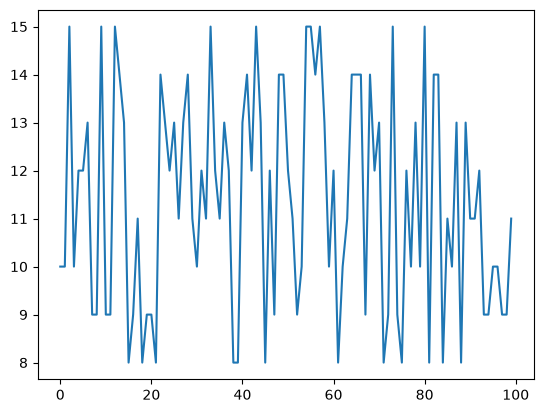

In [7]:
df.英文.plot()

當然, 在這個例子中, 其實畫 histogram 圖更有意義一點。

<Axes: >

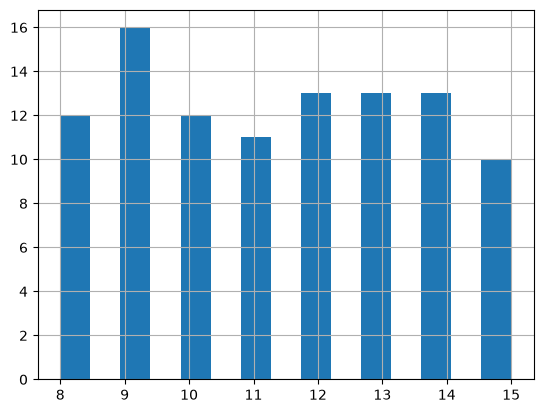

In [8]:
df.英文.hist(bins=15)

## 3 一些基本的資料分析

算平均。

In [9]:
df.英文.mean()

np.float64(11.38)

算標準差。

In [10]:
df.英文.std()

np.float64(2.2731635944807684)

不如就該算的都幫我們算算...

In [11]:
df.describe()

,國文,英文,數學,自然,社會
count,100.000000,100.000000,100.000000,100.00000,100.00000
mean,11.390000,11.380000,11.570000,11.03000,11.83000
std,2.196853,2.273164,2.310516,2.21772,2.48655
min,8.000000,8.000000,8.000000,8.00000,8.00000
25%,9.000000,9.000000,10.000000,9.00000,9.00000
50%,11.000000,11.000000,11.000000,11.00000,12.00000
75%,13.000000,13.000000,14.000000,13.00000,14.00000
max,15.000000,15.000000,15.000000,15.00000,15.00000


有時我們很愛看的相關係數矩陣。

In [12]:
df.corr(numeric_only = True)

,國文,英文,數學,自然,社會
國文,1.000000,0.160158,-0.310899,-0.110236,-0.028421
英文,0.160158,1.000000,0.025656,0.113929,-0.063512
數學,-0.310899,0.025656,1.000000,0.014371,0.041651
自然,-0.110236,0.113929,0.014371,1.000000,-0.156594
社會,-0.028421,-0.063512,0.041651,-0.156594,1.000000


只算兩科間的相關係數當然也可以。

In [13]:
df.國文.corr(df.英文)

np.float64(0.16015801596684315)

## 4 增加一行

### 【技巧】

我們增加一行, 加入總級分。

In [14]:
df["總級分"]= df[["國文", "英文", "數學", "自然", "社會"]].sum(axis=1)
df.head()

,姓名,國文,英文,數學,自然,社會,總級分
0,劉俊安,9,10,15,10,13,57
1,胡玉華,10,10,10,8,9,47
2,黃淑婷,13,15,8,11,14,61
3,陳上紫,10,10,8,9,14,51
4,崔靜成,13,12,14,12,13,64


### 【技巧】

有計算的當然也可以的。

In [15]:
df["加權"] = df.國文 + df.英文 + df.數學 + df.自然 + df.社會*2

In [16]:
df.head()

,姓名,國文,英文,數學,自然,社會,總級分,加權
0,劉俊安,9,10,15,10,13,57,70
1,胡玉華,10,10,10,8,9,47,56
2,黃淑婷,13,15,8,11,14,61,75
3,陳上紫,10,10,8,9,14,51,65
4,崔靜成,13,12,14,12,13,64,77


## 5 排序和 index 重設

### 【重點】排序的方法

我們依總級分來排序。

In [17]:
df.sort_values(by = "總級分", ascending=False).head(10)

,姓名,國文,英文,數學,自然,社會,總級分,加權
80,施雅鈴,13,15,12,13,13,66,79
12,李正偉,11,15,11,14,15,66,81
54,陳怡潔,15,15,9,15,11,65,76
25,蔡亦瑄,13,13,14,13,12,65,77
57,胡淳茜,12,15,14,13,11,65,76
37,曾怡君,11,12,15,13,14,65,79
48,陳怡婷,15,14,12,9,15,65,80
64,俞志峰,9,14,13,14,15,65,80
83,李士賢,10,14,15,13,13,65,78
87,趙偉希,10,13,14,13,15,65,80


### 【重點】排序的方法

加權分最高, 同分才看總級分

In [18]:
df2 = df.sort_values(by = ['總級分','加權'], ascending=False)

### 【重點】重設 index

In [19]:
df2.index =range(1, 101)
df2.head()

,姓名,國文,英文,數學,自然,社會,總級分,加權
1,李正偉,11,15,11,14,15,66,81
2,施雅鈴,13,15,12,13,13,66,79
3,陳怡婷,15,14,12,9,15,65,80
4,俞志峰,9,14,13,14,15,65,80
5,趙偉希,10,13,14,13,15,65,80


## 6 篩出我們要的資料

基本上和 NumPy 的 array 篩法很像。

### 【重點】

找出數學滿級分同學。

In [20]:
df2 = df.copy()
df2[df2.數學==15]

,姓名,國文,英文,數學,自然,社會,總級分,加權
0,劉俊安,9,10,15,10,13,57,70
24,陳竹伯,10,12,15,10,14,61,75
36,詹威德,12,13,15,10,14,64,78
37,曾怡君,11,12,15,13,14,65,79
39,段冠廷,9,8,15,12,15,59,74
59,芮秋辛,11,10,15,10,8,54,62
67,林哲法,14,9,15,10,14,62,76
70,葉儀依,9,13,15,8,14,59,73
73,吳志遠,13,15,15,8,8,59,67
76,周育霖,9,12,15,13,12,61,73


### 【重點】

找出數學和英文都滿級分的同學。要注意 `and` 要用 `&`, `or` 要用 `|`。每個條件一定要加弧號。

## 7 刪除一行或一列

### 【重點】刪掉一行

我們來刪掉總級分的那行。

In [21]:
df2.drop('總級分', axis=1)
df2

,姓名,國文,英文,數學,自然,社會,總級分,加權
0,劉俊安,9,10,15,10,13,57,70
1,胡玉華,10,10,10,8,9,47,56
2,黃淑婷,13,15,8,11,14,61,75
3,陳上紫,10,10,8,9,14,51,65
4,崔靜成,13,12,14,12,13,64,77
...,...,...,...,...,...,...,...,...
95,蔡佳燕,9,10,9,13,14,55,69
96,吳筱婷,8,10,14,10,15,57,72
97,陳家銘,14,9,11,8,12,54,66
98,李明威,15,9,8,9,15,56,71


### 【重點】改變原有的 DataFrame

我們會發現 `pandas` 很多動作都沒有更改原有的 DataFrame, 真的要改要加入

    inplace=True

In [22]:
df2.drop('總級分', axis=1, inplace = True)
df2

,姓名,國文,英文,數學,自然,社會,加權
0,劉俊安,9,10,15,10,13,70
1,胡玉華,10,10,10,8,9,56
2,黃淑婷,13,15,8,11,14,75
3,陳上紫,10,10,8,9,14,65
4,崔靜成,13,12,14,12,13,77
...,...,...,...,...,...,...,...
95,蔡佳燕,9,10,9,13,14,69
96,吳筱婷,8,10,14,10,15,72
97,陳家銘,14,9,11,8,12,66
98,李明威,15,9,8,9,15,71


### 【重點】刪掉一列

刪掉列就是指定要刪去的 index。

In [23]:
df

,姓名,國文,英文,數學,自然,社會,總級分,加權
0,劉俊安,9,10,15,10,13,57,70
1,胡玉華,10,10,10,8,9,47,56
2,黃淑婷,13,15,8,11,14,61,75
3,陳上紫,10,10,8,9,14,51,65
4,崔靜成,13,12,14,12,13,64,77
...,...,...,...,...,...,...,...,...
95,蔡佳燕,9,10,9,13,14,55,69
96,吳筱婷,8,10,14,10,15,57,72
97,陳家銘,14,9,11,8,12,54,66
98,李明威,15,9,8,9,15,56,71


In [24]:
df2.drop(5).head()

,姓名,國文,英文,數學,自然,社會,加權
0,劉俊安,9,10,15,10,13,70
1,胡玉華,10,10,10,8,9,56
2,黃淑婷,13,15,8,11,14,75
3,陳上紫,10,10,8,9,14,65
4,崔靜成,13,12,14,12,13,77


### 【重點】刪掉一列

通常刪掉符合條件的比較合理 (注意是找到要刪掉的部份, 再找出相對的 index)。

In [25]:
df2[df2.姓名=='李士賢']

,姓名,國文,英文,數學,自然,社會,加權
83,李士賢,10,14,15,13,13,78


In [26]:
df2.drop(df2[df2.姓名=='李士賢'].index)

,姓名,國文,英文,數學,自然,社會,加權
0,劉俊安,9,10,15,10,13,70
1,胡玉華,10,10,10,8,9,56
2,黃淑婷,13,15,8,11,14,75
3,陳上紫,10,10,8,9,14,65
4,崔靜成,13,12,14,12,13,77
...,...,...,...,...,...,...,...
95,蔡佳燕,9,10,9,13,14,69
96,吳筱婷,8,10,14,10,15,72
97,陳家銘,14,9,11,8,12,66
98,李明威,15,9,8,9,15,71


### 【例子】 分析 Apple 股價

## 8 真實股價資料

有個從 `Pandas` 獨立出來的套件叫 `pandas-datareader`, 幾經波折, 先是 Yahoo! 的財務資料不能用, 後來又是 Google 的資料不能用, 不過至少現在看來 Yahoo! 還可以使用。

安裝 `pandas-datareader` 就標準 `conda` 安裝:

    conda install pandas-datareader
    
如果裝過, 但很久沒更新就用:

    conda update pandas-datareader

In [27]:
%pip install yfinance

Note: you may need to restart the kernel to use updated packages.


In [28]:
import pandas_datareader.data as pdr
df = pdr.get_data_yahoo('AAPL')

AttributeError: module 'pandas_datareader.data' has no attribute 'get_data_yahoo'

In [29]:
%pip install pandas-datareader

Note: you may need to restart the kernel to use updated packages.


In [30]:
# 為防止網路有問題, 我們把這個檔案以 aapl.csv 存起來, 可以這樣讀入。
# df = pd.read_csv('data/aapl.csv', index_col="Date")

In [31]:
import yfinance as yf

df = yf.download('AAPL', period='1y')

df.head()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2025-10-10,244.367310,255.436421,243.101979,254.001718,61999100
2025-10-13,246.748520,248.771048,244.656243,248.462191,38142900
2025-10-14,246.858124,247.934151,243.799415,245.692432,35478000
2025-10-15,248.422318,250.893201,246.559205,248.571775,33893600
2025-10-16,246.539291,248.123436,244.227838,247.336350,39777000


#### 只要最後 300 個交易日!

In [32]:

df.iloc[-300:]

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2025-10-10,244.367310,255.436421,243.101979,254.001718,61999100
2025-10-13,246.748520,248.771048,244.656243,248.462191,38142900
2025-10-14,246.858124,247.934151,243.799415,245.692432,35478000
2025-10-15,248.422318,250.893201,246.559205,248.571775,33893600
2025-10-16,246.539291,248.123436,244.227838,247.336350,39777000
...,...,...,...,...,...
2026-10-05,332.890015,336.209991,331.649994,332.820007,34400900
2026-10-06,333.630005,334.380005,330.619995,332.279999,30449000


#### 20 日的移動平均

Ticker,AAPL
Date,
2025-10-10,NaN
2025-10-13,NaN
2025-10-14,NaN
2025-10-15,NaN
2025-10-16,NaN
...,...
2026-10-05,332.541000
2026-10-06,333.411501
2026-10-07,334.478001


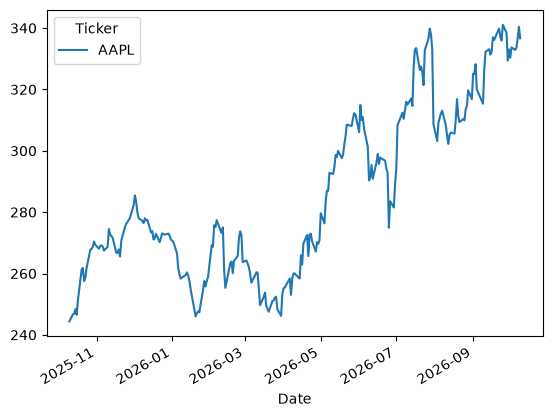

In [33]:
df.Close.plot()
df.Close.rolling(20).mean()


<Axes: xlabel='Date'>

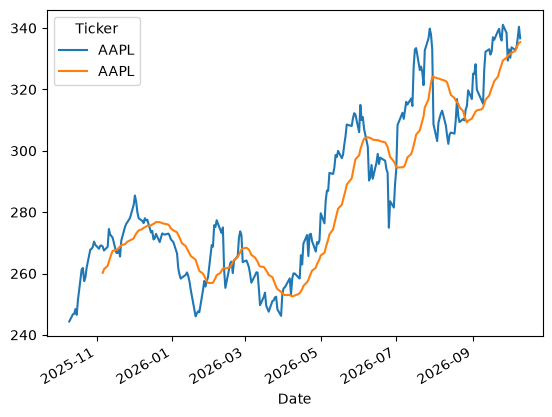

In [34]:
ax = df.Close.plot()
#df.Close.plot()
df.Close.rolling(20).mean().plot(ax=ax)

#### 20 日和 60 日的移動平均

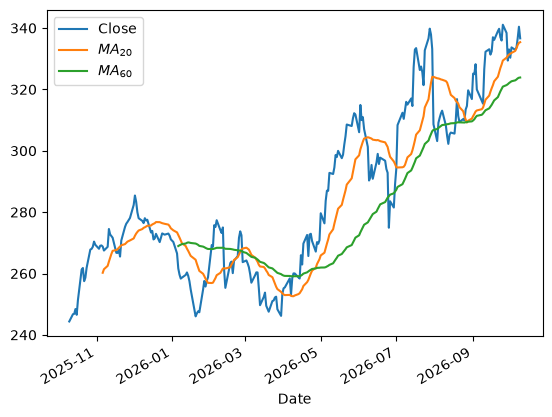

In [35]:
ax = df.Close.plot(legend=True)
df.Close.rolling(20).mean().plot(ax=ax)
df.Close.rolling(60).mean().plot(ax=ax)
ax.legend(["Close", r"$MA_{20}$", r"$MA_{60}$"])

# ax = df.Close.plot(legend=True)

# df.Close.rolling(20).mean().plot(ax=ax)
# df.Close.rolling(60).mean().plot(ax=ax)

# ax.legend(["Close", r"$MA_{20}$", r"$MA_{60}$"])

#### 準備做預測

我們用個非常天真的模型...

![天真股票模型](images/naive.png)

網路上說這是線性的 (可能嗎)!


In [36]:
close = df.Close.values
len(close)

251

In [37]:
x = close[:-1]
len(x)

250

In [38]:
y = close[1:]
len(y)

250

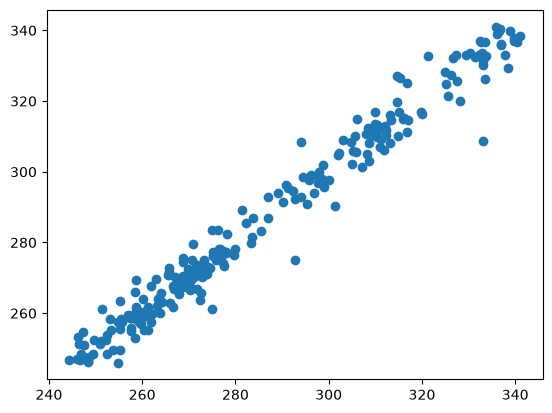

In [39]:
import matplotlib.pyplot as plt
plt.scatter(x,y)

哦, 真的有點像線性的, 我們之後用線性迴歸試試看。

## 9 手工打造一個 DataFrame*

有時我們用手工打造一個簡單的 DataFrame, 可以更理解整個結構。其實很容易, 一個 DataFrame 基本上就包含兩個主要部份:

* 資料本身: 通常一個二維陣列 (矩陣)
* 行、列的名稱

我們來個簡單的小例子。

In [40]:
mydata = np.random.randn(4,3)

In [41]:
mydata

array([[-1.45686167,  0.89719911,  0.80803158],
       [ 1.05070199, -1.12471597,  0.07598314],
       [-1.43230443,  1.50556701, -0.84983833],
       [ 0.17770542,  2.14550893, -0.29610636]])

把行列的名字放進去, 就成一個 DataFrame。我們列的部份先讓 Python 自己產生。

In [42]:
df2 = pd.DataFrame(mydata, columns = list('ABC'))

In [43]:
df2

,A,B,C
0,-1.456862,0.897199,0.808032
1,1.050702,-1.124716,0.075983
2,-1.432304,1.505567,-0.849838
3,0.177705,2.145509,-0.296106


#### 兩個表格上下貼起來

我們再來生一個 DataFrame, 再「貼」起來。

In [44]:
df3 = pd.DataFrame(np.random.randn(3,3), columns=list("ABC"))

In [45]:
df3

,A,B,C
0,-0.479322,-0.081682,-1.840893
1,-0.464240,-1.421642,1.178866
2,0.463538,-0.070175,1.038780


In [46]:
df4 = pd.concat([df2,df3], axis = 0, )

In [47]:
df4

,A,B,C
0,-1.456862,0.897199,0.808032
1,1.050702,-1.124716,0.075983
2,-1.432304,1.505567,-0.849838
3,0.177705,2.145509,-0.296106
0,-0.479322,-0.081682,-1.840893
1,-0.464240,-1.421642,1.178866
2,0.463538,-0.070175,1.038780


前面我們弄得亂七八糟的 index 重設一下。

In [48]:
df4.index = range(7)

In [49]:
df4

,A,B,C
0,-1.456862,0.897199,0.808032
1,1.050702,-1.124716,0.075983
2,-1.432304,1.505567,-0.849838
3,0.177705,2.145509,-0.296106
4,-0.479322,-0.081682,-1.840893
5,-0.464240,-1.421642,1.178866
6,0.463538,-0.070175,1.038780


#### 横向的貼

In [50]:
df5 = pd.concat([df2,df3], axis = 1)

等等, 這大小好像不太對也可以嗎? 答案是可以的!

In [51]:
df5

,A,B,C,A,B,C
0,-1.456862,0.897199,0.808032,-0.479322,-0.081682,-1.840893
1,1.050702,-1.124716,0.075983,-0.464240,-1.421642,1.178866
2,-1.432304,1.505567,-0.849838,0.463538,-0.070175,1.038780
3,0.177705,2.145509,-0.296106,NaN,NaN,NaN


#### 大一點的例子

我們來做前面「假的」學測資料。首先要有「假的」同學名單, 如果有興趣產生很多名字, 可以用這個服務。

[中文姓名產生器](http://www.richyli.com/name/index.asp)

In [52]:
df_names = pd.read_csv("data/names.csv", names = ["姓名"])

In [53]:
df_names.head()

,姓名
0,羅雅慧
1,王紹尹
2,黃季坤
3,許正書
4,張鈞蓮


In [54]:
df_grades = pd.DataFrame(np.random.randint(6,16,(100,5)),
                        columns=['國文','英文','數學','社會','自然'])

In [56]:
#df_grades.to_csv("data/grades2.csv")

In [63]:

df_grades

,國文,英文,數學,社會,自然
0,6,9,14,13,13
1,8,15,7,8,14
2,10,14,6,14,13
3,6,8,7,6,7
4,14,9,12,7,12
...,...,...,...,...,...
95,15,8,11,10,9
96,7,12,6,14,10
97,9,9,15,7,11
98,12,7,10,13,12


In [60]:
df_score = pd.concat([df_names, df_grades],axis = 1)

In [61]:
df_score

,姓名,國文,英文,數學,社會,自然
0,羅雅慧,6,9,14,13,13
1,王紹尹,8,15,7,8,14
2,黃季坤,10,14,6,14,13
3,許正書,6,8,7,6,7
4,張鈞蓮,14,9,12,7,12
...,...,...,...,...,...,...
95,陳君生,15,8,11,10,9
96,曾桂甫,7,12,6,14,10
97,林欣怡,9,9,15,7,11
98,林佳霖,12,7,10,13,12
